# Configuration

In [1]:
# file_name = 'FullSailUniversity.mp3'
# speakers_expected = 7
# file_name = '2025 Q2 Group 1 Meet 1 - Jon Smith.m4a'
# speakers_expected = 7
file_name = '2025 Q2 Group 1 Meet 2 - Mel Reyes.m4a'
speakers_expected = 6

In [2]:
# Jupyter stuff
# See https://ipython.org/ipython-doc/3/config/extensions/autoreload.html
%load_ext autoreload
%autoreload 2

# Actual config
import logging
import os
from pathlib import Path, PurePath

from dotenv import load_dotenv
from lib.config_functions import *

load_dotenv() # Load environment variables

path_base = Path.cwd()
path_media = Path(path_base).joinpath('media')
path_output = Path(path_base).joinpath('output')
path_prompt_templates = Path(path_base).joinpath('prompt_templates')
path_file = Path(path_media).joinpath(file_name)

# Create the working dir for the given file
_file_name_noext = PurePath(path_file).stem # Remove the extension if any
path_work_dir = Path(path_output).joinpath(_file_name_noext)
path_work_dir.mkdir(exist_ok=True)

# Create assemblyai dir
path_transcript_dir = path_work_dir.joinpath('assemblyai_transcript')
path_transcript_dir.mkdir(exist_ok=True)

# Create report dir
path_reports_dir = path_work_dir.joinpath('reports')
path_reports_dir.mkdir(exist_ok=True)

# Configure logger
logger = logging.getLogger('root')
logger.handlers = [] # To allow to run this cell multiple times without creating more loggers
logger_add_handlers_file_stream(logger=logger, level=logging.DEBUG, filename=path_work_dir.joinpath('log.txt'))

# Obtaining audio transcript

In [3]:
import lib.assemblyai_helper_functions as ahf

path_response_upload_json = path_transcript_dir.joinpath('response_upload.json')
path_response_create_json = path_transcript_dir.joinpath('response_create.json')
path_response_transcript_json = path_transcript_dir.joinpath('response_transcript.json')
print(path_response_transcript_json)

transcript = ahf.get_audio_transcript(
    path_file,
    path_response_upload_json=path_response_upload_json,
    path_response_create_json=path_response_create_json,
    path_response_transcript_json=path_response_transcript_json,
    speakers_expected=speakers_expected,
    force=False,
)

INFO:root:assemblyai_helper_functions.py(164):get_audio_transcript 2025-05-07 19:49:18,234
Creating Audio transcript
INFO:root:assemblyai_helper_functions.py(169):get_audio_transcript 2025-05-07 19:49:18,234
Transcript already stored, retrieving from json file.


/Users/felipe/Documents/development/python projects/2025/output/2025 Q2 Group 1 Meet 2 - Mel Reyes/assemblyai_transcript/response_transcript.json


In [4]:
# # Testing

# logging.info('** TESTING STARTED **\n\n\n')

# path_response_upload_json = path_transcript_dir.joinpath('response_upload.json')
# path_response_create_json = path_transcript_dir.joinpath('response_create.json')
# path_response_transcript_json = path_transcript_dir.joinpath('response_transcript.json')

# response_upload_json = ahf._upload_file(path_file, path_response_upload_json, False)
# url_upload = response_upload_json['upload_url']
# logging.info(f'Uploaded URL: {url_upload}')
# response_create_json = ahf._create_transcript(url_upload, path_response_create_json,speakers_expected, False)
# id_transcript = response_create_json['id']
# logging.info(f'Transcript id: {id_transcript}')
# response_transcript_json = ahf._obtain_transcript(
#     id_transcript, path_response_transcript_json, True
# )

# Summarization and Speaker Mapping

In [5]:
import lib.llm_functions as llmfn

speaker_map = llmfn.summarize_and_map_speaker(
    utterances=transcript['utterances'],
    path_work_dir=path_work_dir,
    path_prompt_templates=path_prompt_templates,
    force=False,
)
# speaker_map

INFO:root:llm_functions.py(62):summarize_and_map_speaker 2025-05-07 19:49:18,824
Creating speaker mapping...
DEBUG:root:llm_functions.py(65):summarize_and_map_speaker 2025-05-07 19:49:18,825
...speaker mapping already created, loading mapping from json file [/Users/felipe/Documents/development/python projects/2025/output/2025 Q2 Group 1 Meet 2 - Mel Reyes/speaker_mapping.json]


# Data, Obtaining and computing

## DataFrames creation from transcript

In [6]:
import pandas as pd

df_utter = pd.DataFrame.from_dict(transcript['utterances'])

# Remove speaker 'UNK', from df_utter
UNK_index = df_utter.query('speaker == "UNK"').index
df_utter.drop(index=UNK_index, inplace=True)

# Add word count column
df_utter['word_count'] = df_utter['text'].apply(lambda x: len(x.split(' ')))

# Add target (the next person to speak as a proxy to whom one talked)
df_utter['target'] = df_utter.loc[:, ['speaker']].shift(periods=-1)

# Add previous (the previous person to speak as a proxy to whom one responds)
df_utter['previous'] = df_utter.loc[:, ['speaker']].shift(periods=1)

# Add words per second and per minute
df_utter['talk_time_sec'] = (df_utter['end'] - df_utter['start']) / 1000
df_utter['words_per_sec'] = df_utter['word_count'] / df_utter['talk_time_sec']
df_utter['words_per_min'] = df_utter['words_per_sec'] * 60

df_sentiment = pd.DataFrame.from_dict(transcript['sentiment_analysis_results'])
# Remove speaker 'UNK', from df_sentiment
UNK_index = df_sentiment.query('speaker == "UNK"').index
df_sentiment.drop(index=UNK_index, inplace=True)
# Adding column that maps sentiment to int values
# See the following to understand why the `with ...` statement
# https://github.com/pandas-dev/pandas/issues/57734#issuecomment-2099489978
with pd.option_context('future.no_silent_downcasting', True):
    df_sentiment['sentiment_value'] = (
        df_sentiment['sentiment']
        .astype('object')
        .replace({'NEGATIVE': -1, 'NEUTRAL': 0, 'POSITIVE': 1})
    )

In [7]:
# df_utter.head(6)
# df_sentiment.head(6)
# df_sentiment.query('sentiment == "NEGATIVE" ')

## Speaker stats

In [8]:
import nltk


def idea_count(text: str):
    tokens = nltk.word_tokenize(text)
    words = [word for word, tag in nltk.pos_tag(tokens) if tag == 'MD']
    return len(words)


def unique_words(df: pd.DataFrame):
    # IMPORTANT: Function to be applied to a complete DataFrame, returns a new DataFrame
    # see: https://stackoverflow.com/a/35208597/1071459
    words = df['text'].split()
    unique_words = set(words)
    df['unique_words_count'] = len(unique_words)
    df['unique_words_pct'] = len(unique_words) / len(words)
    return df


# Create a df with all text by the same speaker is joined and with the word count
df_speaker_stats = df_utter.groupby(['speaker']).agg(
    {
        'text': lambda x: ' '.join(x),
        'word_count': lambda x: x.sum(),
        'talk_time_sec': lambda x: x.sum(),
        'words_per_min': lambda x: x.mean(),
    }
)
df_speaker_stats['word_count_pct'] = (
    100 * df_speaker_stats['word_count'] / df_speaker_stats['word_count'].sum()
)
df_speaker_stats['talk_time_pct'] = (
    100 * df_speaker_stats['talk_time_sec'] / df_speaker_stats['talk_time_sec'].sum()
)
df_speaker_stats['question_count'] = df_speaker_stats['text'].apply(lambda x: x.count('?'))
df_speaker_stats['idea_count'] = df_speaker_stats['text'].apply(idea_count)
df_speaker_stats = df_speaker_stats.apply(unique_words, axis=1)

# Adding interaction_count
_interaction_count = df_utter['speaker'].value_counts().rename('interaction_count')
df_speaker_stats = pd.merge(df_speaker_stats, _interaction_count, left_index=True, right_index=True)

# At this point we copy the speaker column to have a backup of the original names
# and we change the index to be named 'named'
df_speaker_stats['speaker'] = df_speaker_stats.index
df_speaker_stats.index.name = 'name'

# Sort columns
df_speaker_stats = df_speaker_stats[
    [
        'speaker',
        'text',
        'word_count',
        'word_count_pct',
        'words_per_min',
        'talk_time_sec',
        'talk_time_pct',
        'question_count',
        'idea_count',
        'unique_words_count',
        'unique_words_pct',
        'interaction_count',
    ]
]
# df_speaker_stats

In [9]:
# df_speaker_stats
# df_utter

## Mapping id to real name

In [10]:
# df_speaker_stats.reset_index().set_index('name')
map_speaker_to_name = {key: speaker_map[key]['name'] for key in speaker_map}

df_sentiment['name'] = df_sentiment['speaker'].replace(map_speaker_to_name)

df_utter['name'] = df_utter['speaker'].replace(map_speaker_to_name)
df_utter['name_target'] = df_utter['target'].replace(map_speaker_to_name)
df_utter['name_previous'] = df_utter['previous'].replace(map_speaker_to_name)

df_speaker_stats.reset_index(drop=True,inplace=True)
df_speaker_stats['name'] = df_speaker_stats['speaker'].replace(map_speaker_to_name)
df_speaker_stats = df_speaker_stats.set_index('name')

In [11]:
# df_sentiment.head(4)
# df_utter.head(4)
# df_speaker_stats

## Speaker interactions

In [12]:
# Interactions from name to name_target
# interesting because it shows how many interactions happened
df_interactions_next = pd.crosstab(df_utter['name'], df_utter['name_target'], margins=True)
df_interactions_next

name_target,Brandy,Daion,Felipe,Jason,Mel,Rodrigo,All
name,,,,,,,
Brandy,0,5,3,7,5,0,20
Daion,4,0,2,2,10,3,21
Felipe,4,1,0,9,8,3,25
Jason,7,2,11,0,8,13,41
Mel,4,9,6,12,0,9,40
Rodrigo,1,4,2,11,10,0,28
All,20,21,24,41,41,28,175


In [13]:
# Interactions from name to name_previous
# interesting because it shows how many interactions happened
df_interactions_prev = pd.crosstab(df_utter['name'], df_utter['name_previous'], margins=True)
df_interactions_prev

name_previous,Brandy,Daion,Felipe,Jason,Mel,Rodrigo,All
name,,,,,,,
Brandy,0,4,4,7,4,1,20
Daion,5,0,1,2,9,4,21
Felipe,3,2,0,11,6,2,24
Jason,7,2,9,0,12,11,41
Mel,5,10,8,8,0,10,41
Rodrigo,0,3,3,13,9,0,28
All,20,21,25,41,40,28,175


In [14]:
# Words spoken from name to name_target
# interesting because it shows how the interactions went
df_interactions_next_wrd_cnt = pd.crosstab(
    index=df_utter['name'],
    columns=df_utter['name_target'],
    values=df_utter['word_count'],
    aggfunc='sum',
    margins=True,
).fillna(0).astype('int')
df_interactions_next_wrd_cnt

name_target,Brandy,Daion,Felipe,Jason,Mel,Rodrigo,All
name,,,,,,,
Brandy,0,418,10,80,475,0,983
Daion,185,0,13,7,160,215,580
Felipe,40,17,0,50,854,86,1047
Jason,373,65,764,0,565,228,1995
Mel,1270,1515,617,240,0,1915,5557
Rodrigo,2,273,2,80,882,0,1239
All,1870,2288,1406,457,2936,2444,11401


In [15]:
# Words spoken from name to name_previous
# interesting because it shows how the interactions went
df_interactions_prev_wrd_cnt = pd.crosstab(
    index=df_utter['name'],
    columns=df_utter['name_previous'],
    values=df_utter['word_count'],
    aggfunc='sum',
    margins=True,
).fillna(0).astype('int')
df_interactions_prev_wrd_cnt

name_previous,Brandy,Daion,Felipe,Jason,Mel,Rodrigo,All
name,,,,,,,
Brandy,0,14,409,105,446,9,983
Daion,31,0,11,3,282,253,580
Felipe,54,11,0,154,791,32,1042
Jason,86,4,62,0,610,1233,1995
Mel,666,1502,1705,424,0,1261,5558
Rodrigo,0,13,273,693,260,0,1239
All,837,1544,2460,1379,2389,2788,11397


# Report components

## Compute Gini Coefficient, various possibilities

In [16]:
# # Test Gini coef
# import lib.helper_functions as hf
# hf.gini([30/16]*16 + [40/8]*8 + [50/4]*4 + [60/2]*2 + [70]) # Should be 0.6038709677419355

### Number of interactions by each participan

Gini, Number of interactions by each participan
gini: 0.16 [1-gini]: 0.84


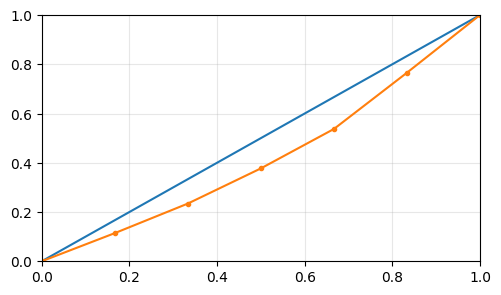

In [17]:
import lib.helper_functions as hf
# Calculate gini only with number of interactions per participants
# (take the 'All' column of df_interactions_next without the last [total] column)
print('Gini, Number of interactions by each participan')
print(
    'gini:',
    round(hf.gini(df_interactions_next['All'][:-1].to_list()), 2),
    '[1-gini]:',
    round(1 - hf.gini(df_interactions_next['All'][:-1].to_list()), 2),
)
fig = hf.gini_plot(df_interactions_next['All'][:-1].to_list())

### Number of every interaction between every participant

Gini, Number of every interaction between every participant
gini: 0.36 [1-gini]: 0.64


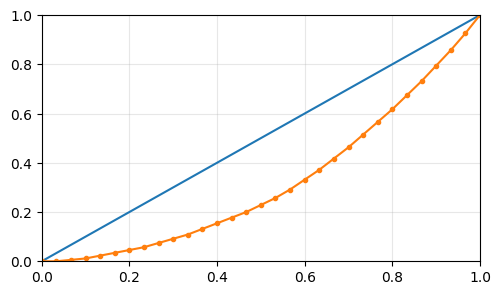

In [18]:
import lib.helper_functions as hf

# IMPORTANT: df_interactions_next and df_interactions_prev produce the same results
# as the contain the same numbers only transposed

_df = df_interactions_next.iloc[:-1, :-1]  # We remove one to avoid the All column or row
size = _df.shape[0]
for i in range(size):
    # print(_df.iat[i, i])
    _df.iat[i, i] = pd.NA
_list = _df.melt()['value'].dropna().tolist()
print('Gini, Number of every interaction between every participant')
print(
    'gini:',
    round(hf.gini(_list), 2),
    '[1-gini]:',
    round(1 - hf.gini(_list), 2),
)
fig = hf.gini_plot(_list)

### Number of words between every participant, taking to the next person

Gini, Number of words between every participant, taking to the next person
gini: 0.62 [1-gini]: 0.38


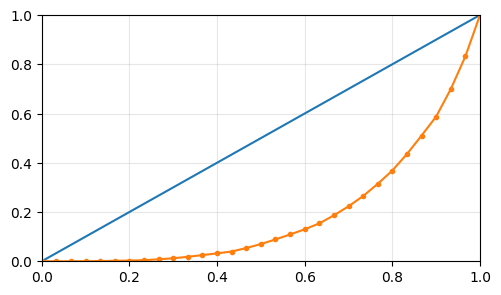

In [19]:
import lib.helper_functions as hf

_df = df_interactions_next_wrd_cnt.iloc[:-1, :-1]  # We remove one to avoid the All column or row
size = _df.shape[0]
for i in range(size):
    # print(_df.iat[i, i])
    _df.iat[i, i] = pd.NA
_list = _df.melt()['value'].dropna().tolist()
print('Gini, Number of words between every participant, taking to the next person')
print(
    'gini:',
    round(hf.gini(_list), 2),
    '[1-gini]:',
    round(1 - hf.gini(_list), 2),
)
fig = hf.gini_plot(_list)

### Number of words between every participant, taking to the previous person

Gini, Number of words between every participant, taking to the previous person
gini: 0.63 [1-gini]: 0.37


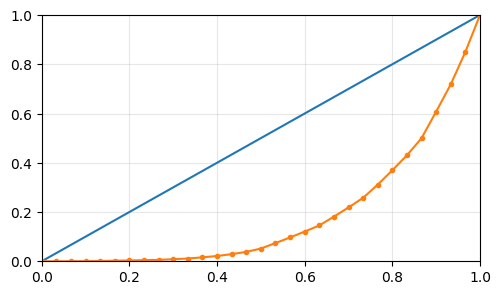

In [20]:
import lib.helper_functions as hf

_df = df_interactions_prev_wrd_cnt.iloc[:-1, :-1]  # We remove one to avoid the All column or row
size = _df.shape[0]
for i in range(size):
    # print(_df.iat[i, i])
    _df.iat[i, i] = pd.NA
_list = _df.melt()['value'].dropna().tolist()
print('Gini, Number of words between every participant, taking to the previous person')
print(
    'gini:',
    round(hf.gini(_list), 2),
    '[1-gini]:',
    round(1 - hf.gini(_list), 2),
)
fig = hf.gini_plot(_list)

### (TESTING COMMENT PERSON) Number of words between every participant, taking to the previous person

In [21]:
# import matplotlib.pyplot as plt
# import numpy as np
# import lib.helper_functions as hf

# _df = df_interactions_prev_wrd_cnt.iloc[:-1, :-1]  # We remove one to avoid the All column or row
# # COMMENT A PARTICIPAN BELOW
# person_select = [
#     0,
#     1,
#     2,
#     3,
#     4,
#     5,
#     # 6,
#     # 7,
# ]
# _df = _df.iloc[person_select, person_select]
# size = _df.shape[0]
# for i in range(size):
#     # print(_df.iat[i, i])
#     _df.iat[i, i] = pd.NA
# _list = _df.melt()['value'].dropna().tolist()
# print(
#     'gini:',
#     round(hf.gini(_list), 2),
#     '[1-gini]:',
#     round(1 - hf.gini(_list), 2),
# )
# fig = hf.gini_plot(_list)

## Plots

In [22]:
import lib.helper_functions as hf
%config InlineBackend.figure_format = "retina"

### Participation Balance

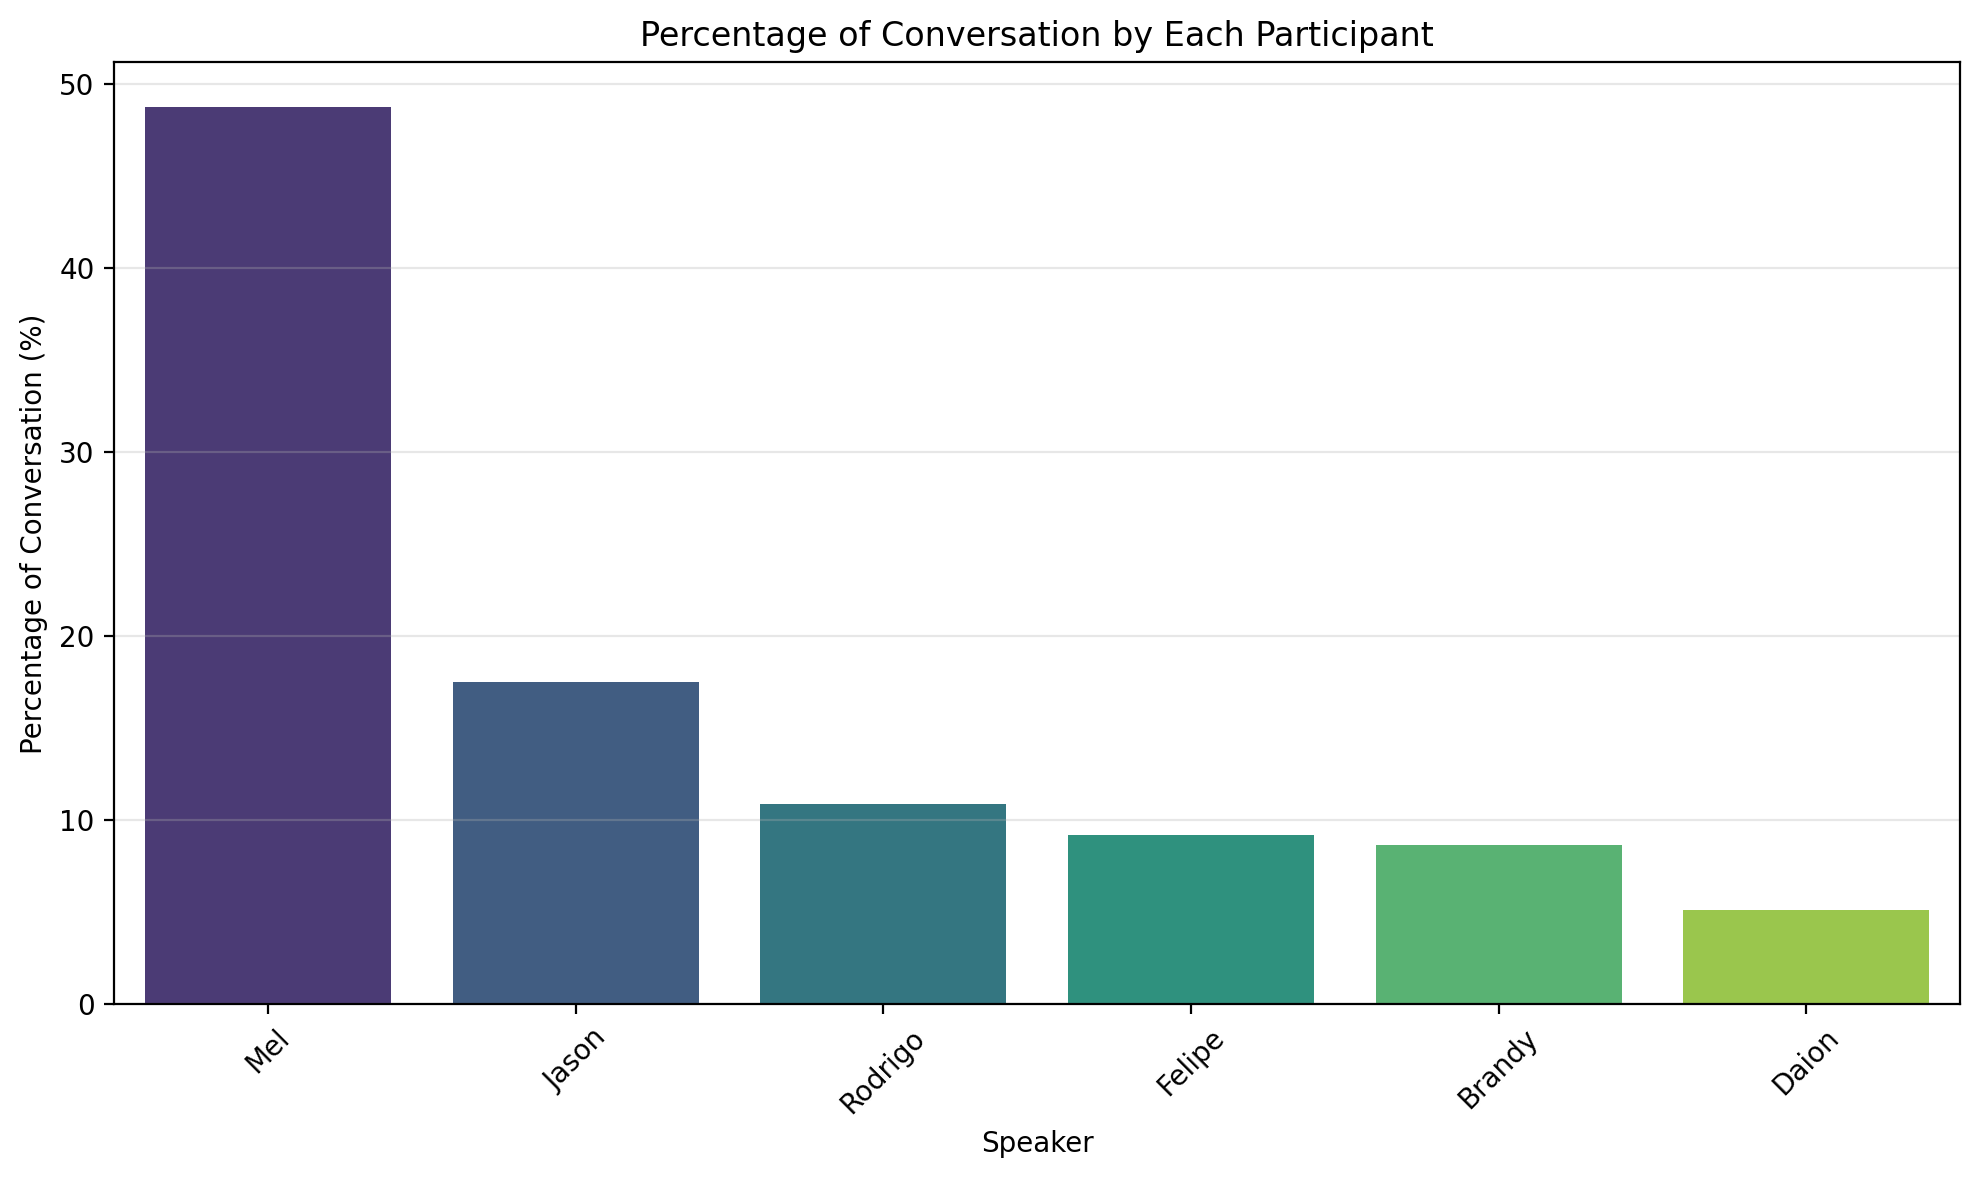

In [23]:
fig_part_balance = hf.barplot(
    data=df_speaker_stats[['word_count_pct']]
    .sort_values(by='word_count_pct', ascending=False)
    .transpose(),
    title='Percentage of Conversation by Each Participant',
    xlabel='Speaker',
    ylabel='Percentage of Conversation (%)',
)

### Words per minute

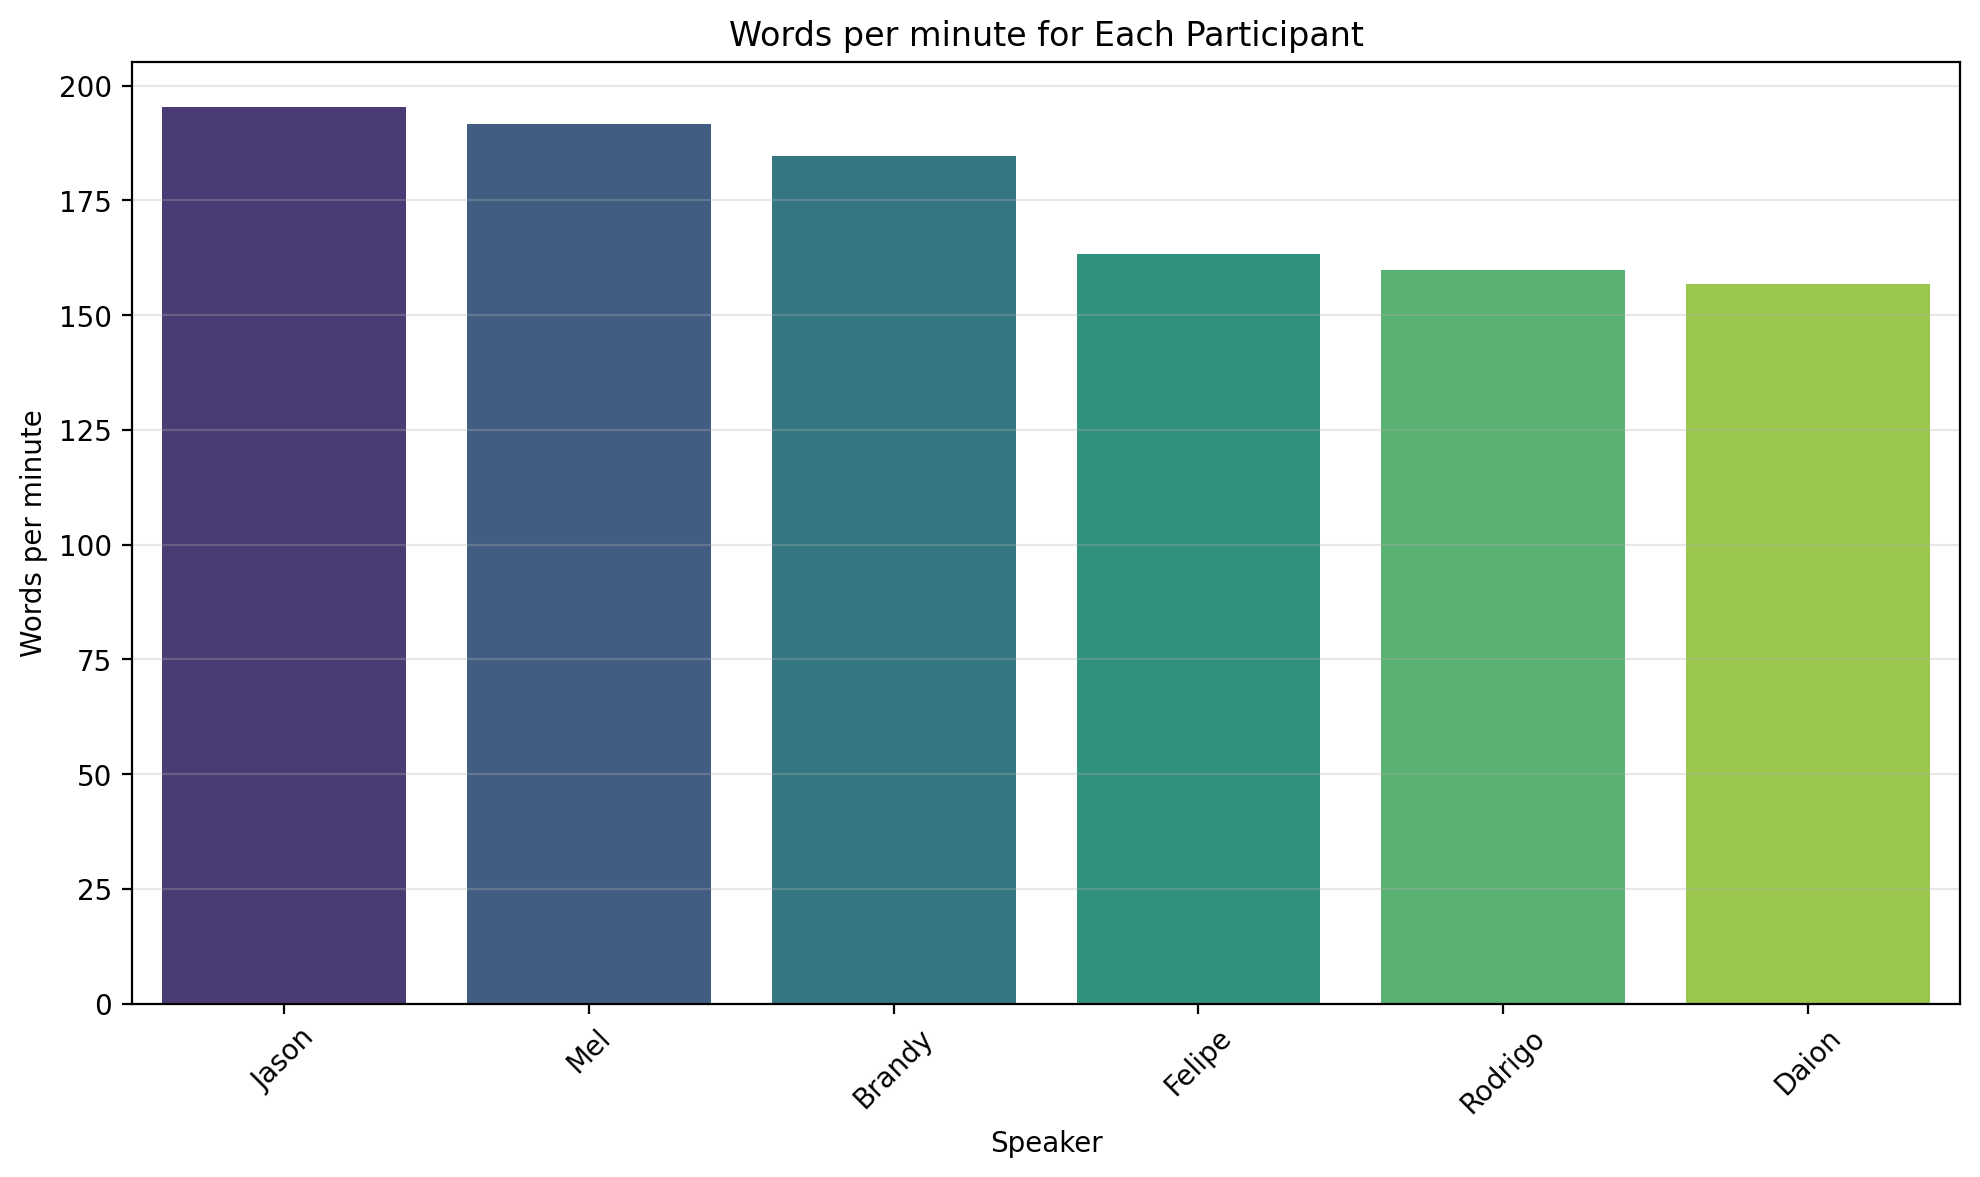

In [24]:
fig_word_per_min = hf.barplot(
    data=df_speaker_stats[['words_per_min']]
    .sort_values(by='words_per_min', ascending=False)
    .transpose(),
    title='Words per minute for Each Participant',
    xlabel='Speaker',
    ylabel='Words per minute',
)

### Idea generation

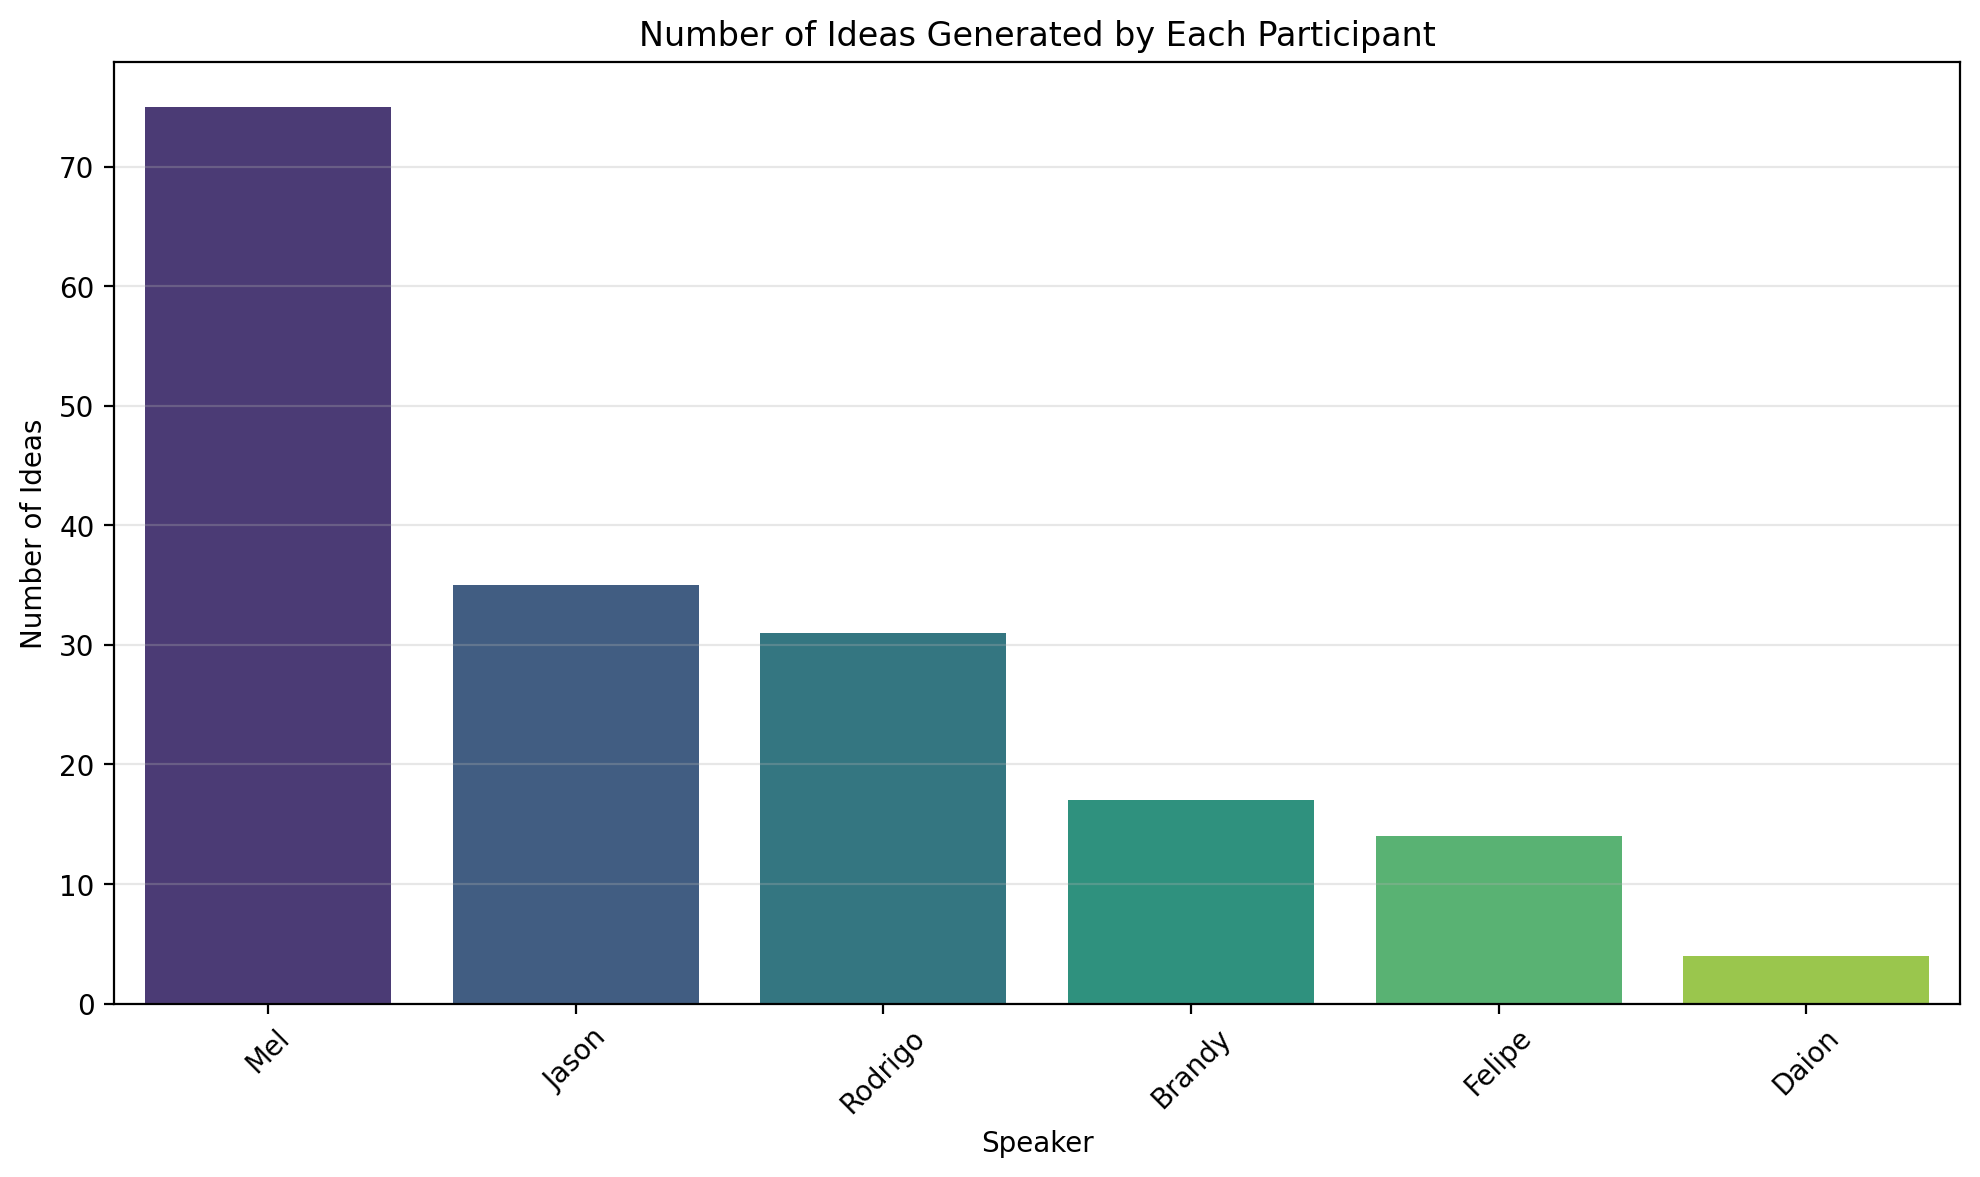

In [25]:
fig_idea_count = hf.barplot(
    data=df_speaker_stats[['idea_count']]
    .sort_values(by='idea_count', ascending=False)
    .transpose(),
    title='Number of Ideas Generated by Each Participant',
    xlabel='Speaker',
    ylabel='Number of Ideas',
)

### Unique words

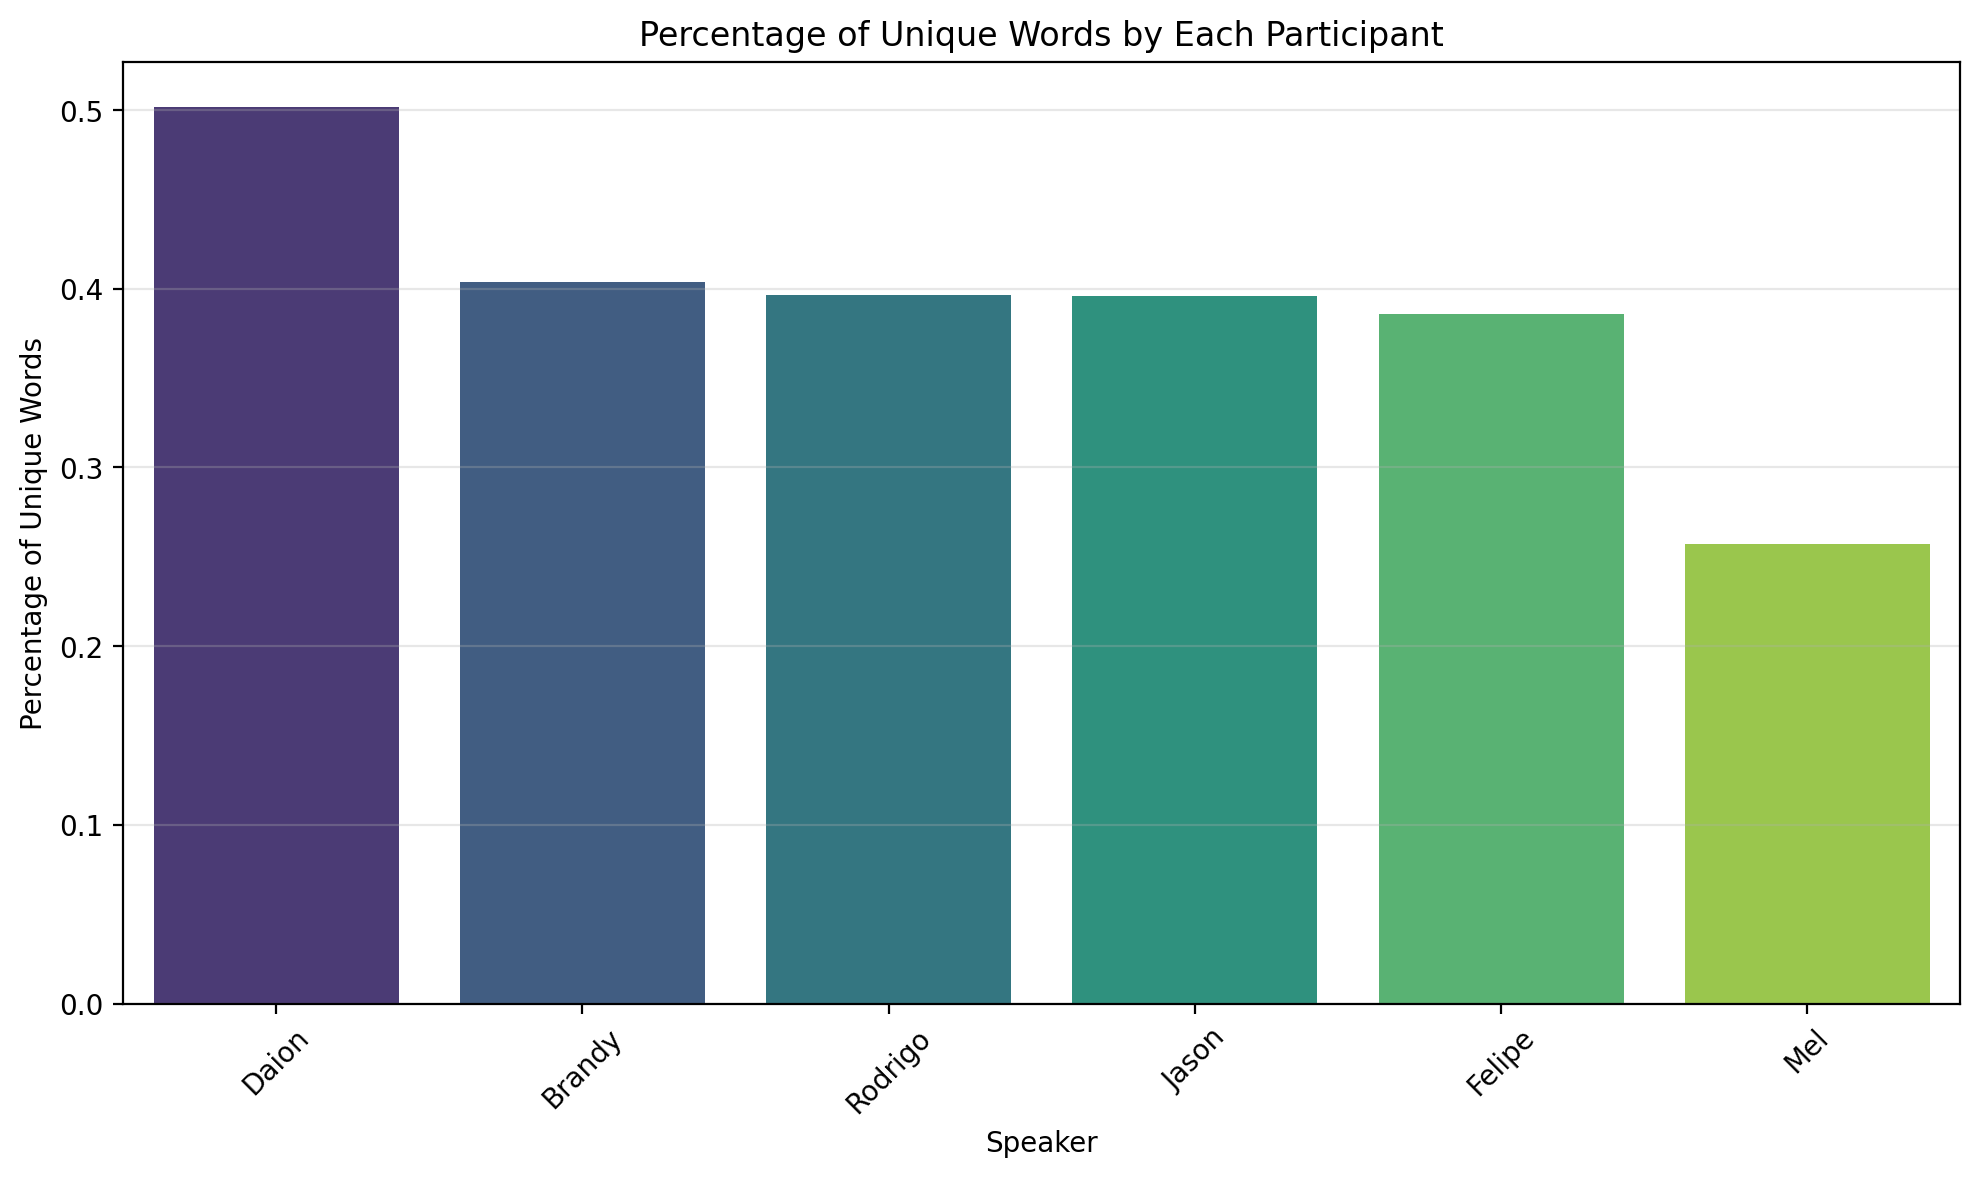

In [26]:
fig_idea_count = hf.barplot(
    data=df_speaker_stats[['unique_words_pct']]
    .sort_values(by='unique_words_pct', ascending=False)
    .transpose(),
    title='Percentage of Unique Words by Each Participant',
    xlabel='Speaker',
    ylabel='Percentage of Unique Words',
)

## Chord diagram

In [27]:
# df_utter.head(2)

In [28]:
names_label = df_interactions_next.iloc[:-1, :-1]
# names = names_label.index.to_list()
# matrix = names_label.values.tolist()
# matrix, names
names_label

name_target,Brandy,Daion,Felipe,Jason,Mel,Rodrigo
name,,,,,,
Brandy,0,5,3,7,5,0
Daion,4,0,2,2,10,3
Felipe,4,1,0,9,8,3
Jason,7,2,11,0,8,13
Mel,4,9,6,12,0,9
Rodrigo,1,4,2,11,10,0


In [29]:
from plotapi import Chord

_df_interaction = df_interactions_next.iloc[:-1, :-1]

c = Chord(
    matrix=_df_interaction.values.tolist(),
    names=_df_interaction.index.to_list(),
    padding=0.5,
    curved_labels=True,
    conjunction="&",
    verb="interacted",
    noun="times",
    popup_width=100,
)

c.show()
c.to_html(path_work_dir.joinpath('chord.html'))
# from IPython.display import IFrame
# IFrame(f'file://{path_work_dir.joinpath('chord.html')}', 900, 500)

DEBUG:urllib3.connectionpool:connectionpool.py(1049):_new_conn 2025-05-07 19:49:20,495
Starting new HTTPS connection (1): plotapi.com:443
DEBUG:urllib3.connectionpool:connectionpool.py(544):_make_request 2025-05-07 19:49:21,320
https://plotapi.com:443 "POST /chord/ HTTP/1.1" 200 None


DEBUG:urllib3.connectionpool:connectionpool.py(544):_make_request 2025-05-07 19:49:21,539
https://plotapi.com:443 "POST /chord/ HTTP/1.1" 200 None


## Colored Speaker Stats

In [30]:
col_name = {
    # 'speaker': 'speaker',
    # 'text': 'text',
    'word_count': 'Word Count',
    # 'word_count_pct': 'word_count_pct',
    'words_per_min': 'Word Per Minute (WPM)',
    # 'talk_time_sec': 'talk_time_sec',
    'talk_time_pct': 'Speaking Time (%)',
    'question_count': 'Questions Asked',
    'idea_count': 'Idea Generation',
    # 'unique_words_count': 'unique_words_count',
    'unique_words_pct': 'Unique Words % (Idea Density)',
    'interaction_count': 'Total Interactions'
}

In [31]:
nice_stats_data = (
    df_speaker_stats[col_name.keys()]
    .rename(columns=col_name)
    .sort_index(axis=0)
    # .query('name != "Mel" and name != "Jason"')
)
nice_stats_data['Unique Words % (Idea Density)'] = nice_stats_data['Unique Words % (Idea Density)'] * 100
# nice_stats_data.loc['MIN'] = nice_stats_data.min()
nice_stats_data.loc['MEAN'] = nice_stats_data.mean()
# nice_stats_data.loc['MAX'] = nice_stats_data.max()
nice_stats_data = nice_stats_data.transpose()

In [32]:
# Beautify
(
    nice_stats_data
    .astype('int')
    .style
    # .format("{:.2f}")

    # .bar(axis=1, cmap='viridis', width=100, height=80)

    # .background_gradient(cmap='viridis', axis=1)
    # .background_gradient(cmap='PiYG', axis=1)
    # .background_gradient(cmap='bwr_r', axis=1)
    # .background_gradient(cmap='GnBu', axis=1)
    # .background_gradient(cmap='PuBuGn', axis=1)
    # .background_gradient(cmap='BuGn', axis=1)
    # .background_gradient(cmap='YlGn', axis=1)
    
    .highlight_max(axis=1, color='pink').highlight_min(axis=1, color='powderblue')
)

name,Brandy,Daion,Felipe,Jason,Mel,Rodrigo,MEAN
Word Count,983,580,1047,1995,5558,1239,1900
Word Per Minute (WPM),184,156,163,195,191,159,175
Speaking Time (%),7,4,10,18,47,11,16
Questions Asked,9,12,5,22,77,8,22
Idea Generation,17,4,14,35,75,31,29
Unique Words % (Idea Density),40,50,38,39,25,39,39
Total Interactions,20,21,25,41,41,28,29


In [33]:
nice_stats_html = nice_stats_data.astype('int').style.format("{:.2f}").to_html(justify='right')

## Key Contributions

In [34]:
import textwrap
for speaker in speaker_map:
    print('\n\n', speaker_map[speaker]['name'])
    for quote in speaker_map[speaker]['quotes']:
        print('*', quote['tagline'])
        print(textwrap.fill(quote['quote'], width=100))



 Felipe
* Understanding Motivational Styles Through Ayurveda
So the first one is like wind is like go all over the place, it changes a lot. Second one is like
fire. It's like it, it works, it creates, it, it stays motivated. It creates. And the, the last one
is Earth. Now it's, it, it also creates, but it takes time and it really process things in a slow
manner but like in a really like deep way.
* The Enneagram and the Importance of Self-Giving
So there's another concept called the enneagram...I feel like you're maybe you're like a two and you
want. And you're a giver. So one thing about the twos is that you give a lot because you want the
world to give back to you. So maybe you're, you need to think about also giving to yourself instead
of trying to give to others.
* Focusing on Impact and Clear Communication
maybe instead of you trying to tell what you're good at, it would be pretty cool if you had someone
tell it for you...Like, because that, that gives you like a, like, I don't 

## Summary by participan

In [35]:
import textwrap

for speaker in speaker_map:
    print('\n\n', speaker_map[speaker]['name'])
    print(textwrap.fill(speaker_map[speaker]['summary'], width=100)) # Remove `textwrap.fill` to not have line breaks
    # print(speaker_map[speaker]['summary'])



 Felipe
The speaker offers feedback based on observations of the subject's personality and work style.
Using the Ayurvedic dosha system and the Enneagram personality model, the speaker suggests the
subject, identified as a "wind" type and a "two" (giver), might benefit from collaborating with
individuals possessing complementary personality traits to achieve better balance and focus.
Additionally, the speaker advises the subject to re-structure their LinkedIn profile to highlight
their skills and value proposition more directly, and to consider letting others articulate their
strengths instead of self-promoting.  Finally, the speaker proposes a thought experiment to clarify
the subject's ultimate career goals.


 Jason
This meeting began with a breakout session prompting participants to share a personal story.
Following this, the group discussed a moment where words significantly impacted an outcome, using
personal anecdotes.  The latter half of the meeting focused on feedback for Me

## Action items

In [36]:
import textwrap
for speaker in speaker_map:
    print('\n\n', speaker_map[speaker]['name'])
    for action in speaker_map[speaker]['actions']:
        print('*', action['title'])
        print(textwrap.fill(action['action'], width=100))



 Felipe
* Explore Complementary Work Styles
Seek out collaborations with individuals possessing different work styles to balance your fast-paced
approach.
* Incorporate Self-Care into Giving
Prioritize self-care alongside your focus on helping others, ensuring a balance between giving to
others and giving to yourself.
* Refine LinkedIn Profile for Clarity
Revise your LinkedIn profile to highlight your key skills and value proposition more directly,
focusing on what you offer potential employers.
* Solicit External Validation of Skills
Seek feedback from others to identify and articulate your strengths and accomplishments.


 Jason
* Refine Personal Narrative for Business
Refine personal narrative to highlight problem-solving skills and value proposition for potential
investors, focusing on impact and results rather than solely on personal attributes.
* Develop Targeted Messaging
Develop concise and impactful messaging that clearly communicates the value proposition and problem-
solvi

# PDF generation

In [37]:
from fpdf import FPDF

# Images in FPDF: https://py-pdf.github.io/fpdf2/Images.html

from PIL import Image
import io

# Save figure to an in-memory bytes buffer
buf = io.BytesIO()
fig_part_balance.savefig(buf, format='png', bbox_inches='tight')
buf.seek(0)  # Important: go to the start of the buffer

# Open as PIL Image directly from memory
image = Image.open(buf)

pdf = FPDF(format='letter')
pdf.add_page()
pdf.set_font('Helvetica', size=12)
pdf.cell(text="Hello world!")
# pdf.cell(text="Hello world!")
pdf.image(
    image,
    # x=20,
    # y=60,
    w=pdf.epw / 2,
)
pdf.write_html(nice_stats_html)

pdf.output(path_reports_dir.joinpath("report_test.pdf"))

DEBUG:PIL.PngImagePlugin:PngImagePlugin.py(200):call 2025-05-07 19:49:21,929
STREAM b'IHDR' 16 13
DEBUG:PIL.PngImagePlugin:PngImagePlugin.py(200):call 2025-05-07 19:49:21,929
STREAM b'tEXt' 41 58
DEBUG:PIL.PngImagePlugin:PngImagePlugin.py(200):call 2025-05-07 19:49:21,930
STREAM b'pHYs' 111 9
DEBUG:PIL.PngImagePlugin:PngImagePlugin.py(200):call 2025-05-07 19:49:21,930
STREAM b'IDAT' 132 26249
DEBUG:fpdf.output:output.py(1333):_log_final_sections_sizes 2025-05-07 19:49:21,972
Final size summary of the biggest document sections:
DEBUG:fpdf.output:output.py(1335):_log_final_sections_sizes 2025-05-07 19:49:21,972
- pages: 1.0KiB
DEBUG:fpdf.output:output.py(1335):_log_final_sections_sizes 2025-05-07 19:49:21,973
- fonts: 199.0B
DEBUG:fpdf.output:output.py(1335):_log_final_sections_sizes 2025-05-07 19:49:21,973
- images: 25.8KiB


# IDEAS

## Visualize Chapters

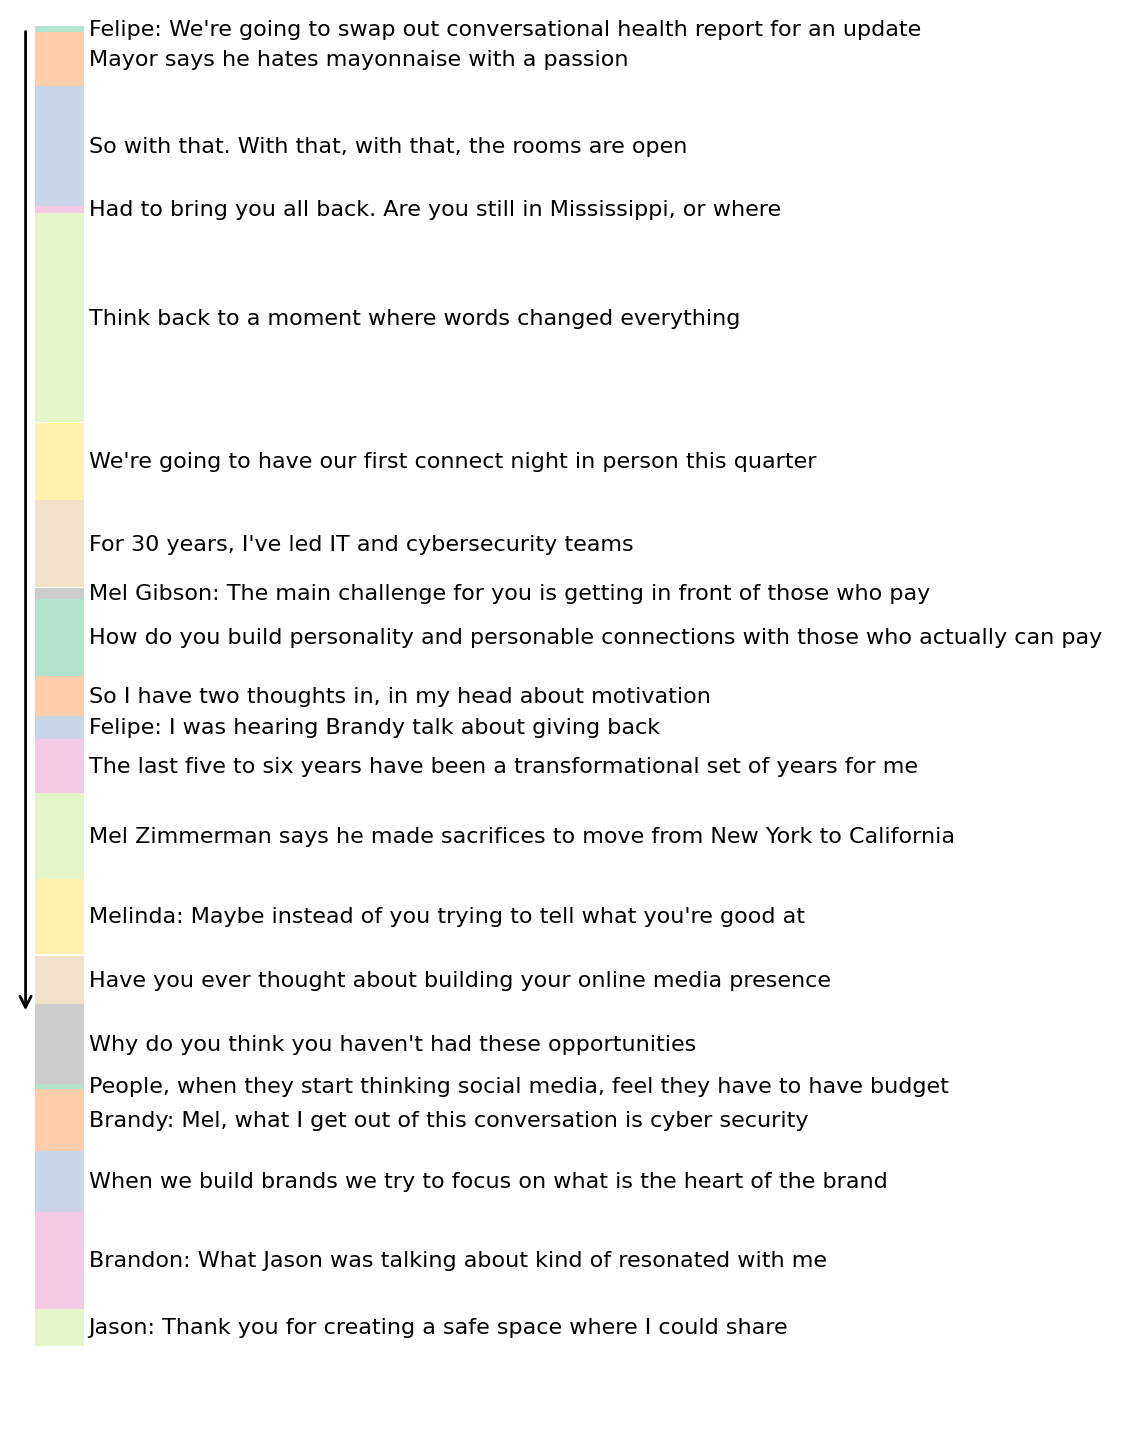

In [38]:
import numpy as np
import matplotlib.pyplot as plt

chap_times = np.ndarray(0)
texts = np.ndarray(0)

for chap in transcript['chapters']:
    # print(chap)
    start = chap['start']
    end = chap['end']
    duration = chap['end'] - chap['start']
    middle_point = int(start + duration / 2)
    # chap_times.append((start, end, end-start))
    chap_times = np.append(chap_times, (start, end, duration, middle_point))
    texts = np.append(texts, chap['headline'])

    # # Vertical bar
    # plt.text(0.5, -middle_point, chap['headline'])

# Unnecessary for plot, scale is computed automatically
# but transforms into seconds
chap_times = np.array(chap_times) / 1000

chap_times.shape = [len(transcript['chapters']), 4]
starts = chap_times[:, 0]
ends = chap_times[:, 1]
durations = chap_times[:, 2]
middle_points = chap_times[:, 3]

# See https://ultrapythonic.com/colormaps-in-matplotlib/
# colors = plt.get_cmap('tab20c').colors
# colors = plt.get_cmap('Pastel1').colors
colors = plt.get_cmap('Pastel2').colors
# colors = plt.get_cmap('Set3').colors

# Horizontal bar
# plt.figure(figsize=(10, 1))
# plt.ylim(-0.8, 0.8)
# plt.barh([0], durations, left=starts, height=1, color=colors)
# plt.annotate("", xytext=(0, -0.7), xy=(ends[-1]* (3/4), -0.7), arrowprops=dict(arrowstyle="->"))
# for mid, txt in zip(middle_points, texts):
#     plt.text(mid, 0.6, txt, size=8, rotation=45)

# # Vertical bar
plt.figure(figsize=(0.5, 9))
plt.xlim(-0.8, 0.8)
plt.bar([0], -durations, bottom=-starts, width=1, color=colors)
plt.annotate("", xytext=(-0.7, 0), xy=(-0.7, -ends[-1]* (3/4)), arrowprops=dict(arrowstyle="->"))
for mid, txt in zip(middle_points, texts):
    plt.text(0.6, -mid, txt, size=8, verticalalignment='center')

plt.axis('off');

## Sentiment evolution

In [39]:
df_sentiment['sentiment'].value_counts(normalize=True)

sentiment
NEUTRAL     0.738011
POSITIVE    0.154529
NEGATIVE    0.107460
Name: proportion, dtype: float64

In [40]:
# # df_sentiment['sentiment'].replace({'NEGATIVE':-1, 'NEUTRAL':0, 'POSITIVE': 1})
# df_sentiment['sentiment_value'] = df_sentiment['sentiment'].replace({'NEGATIVE':-1, 'NEUTRAL':0, 'POSITIVE': 1})
# # ax = df_sentiment['sentiment_value'].plot()
# ax = df_sentiment['sentiment_value'].rolling(window=50).mean().plot()
# ax.set_ylim(-1, 1)
# ax.axhline(y=0, color='gray', linestyle='--', linewidth=1)
# # df_sentiment['sentiment_value'].plot()

In [41]:
df_sentiment['sentiment_value'].shape[0]

1126

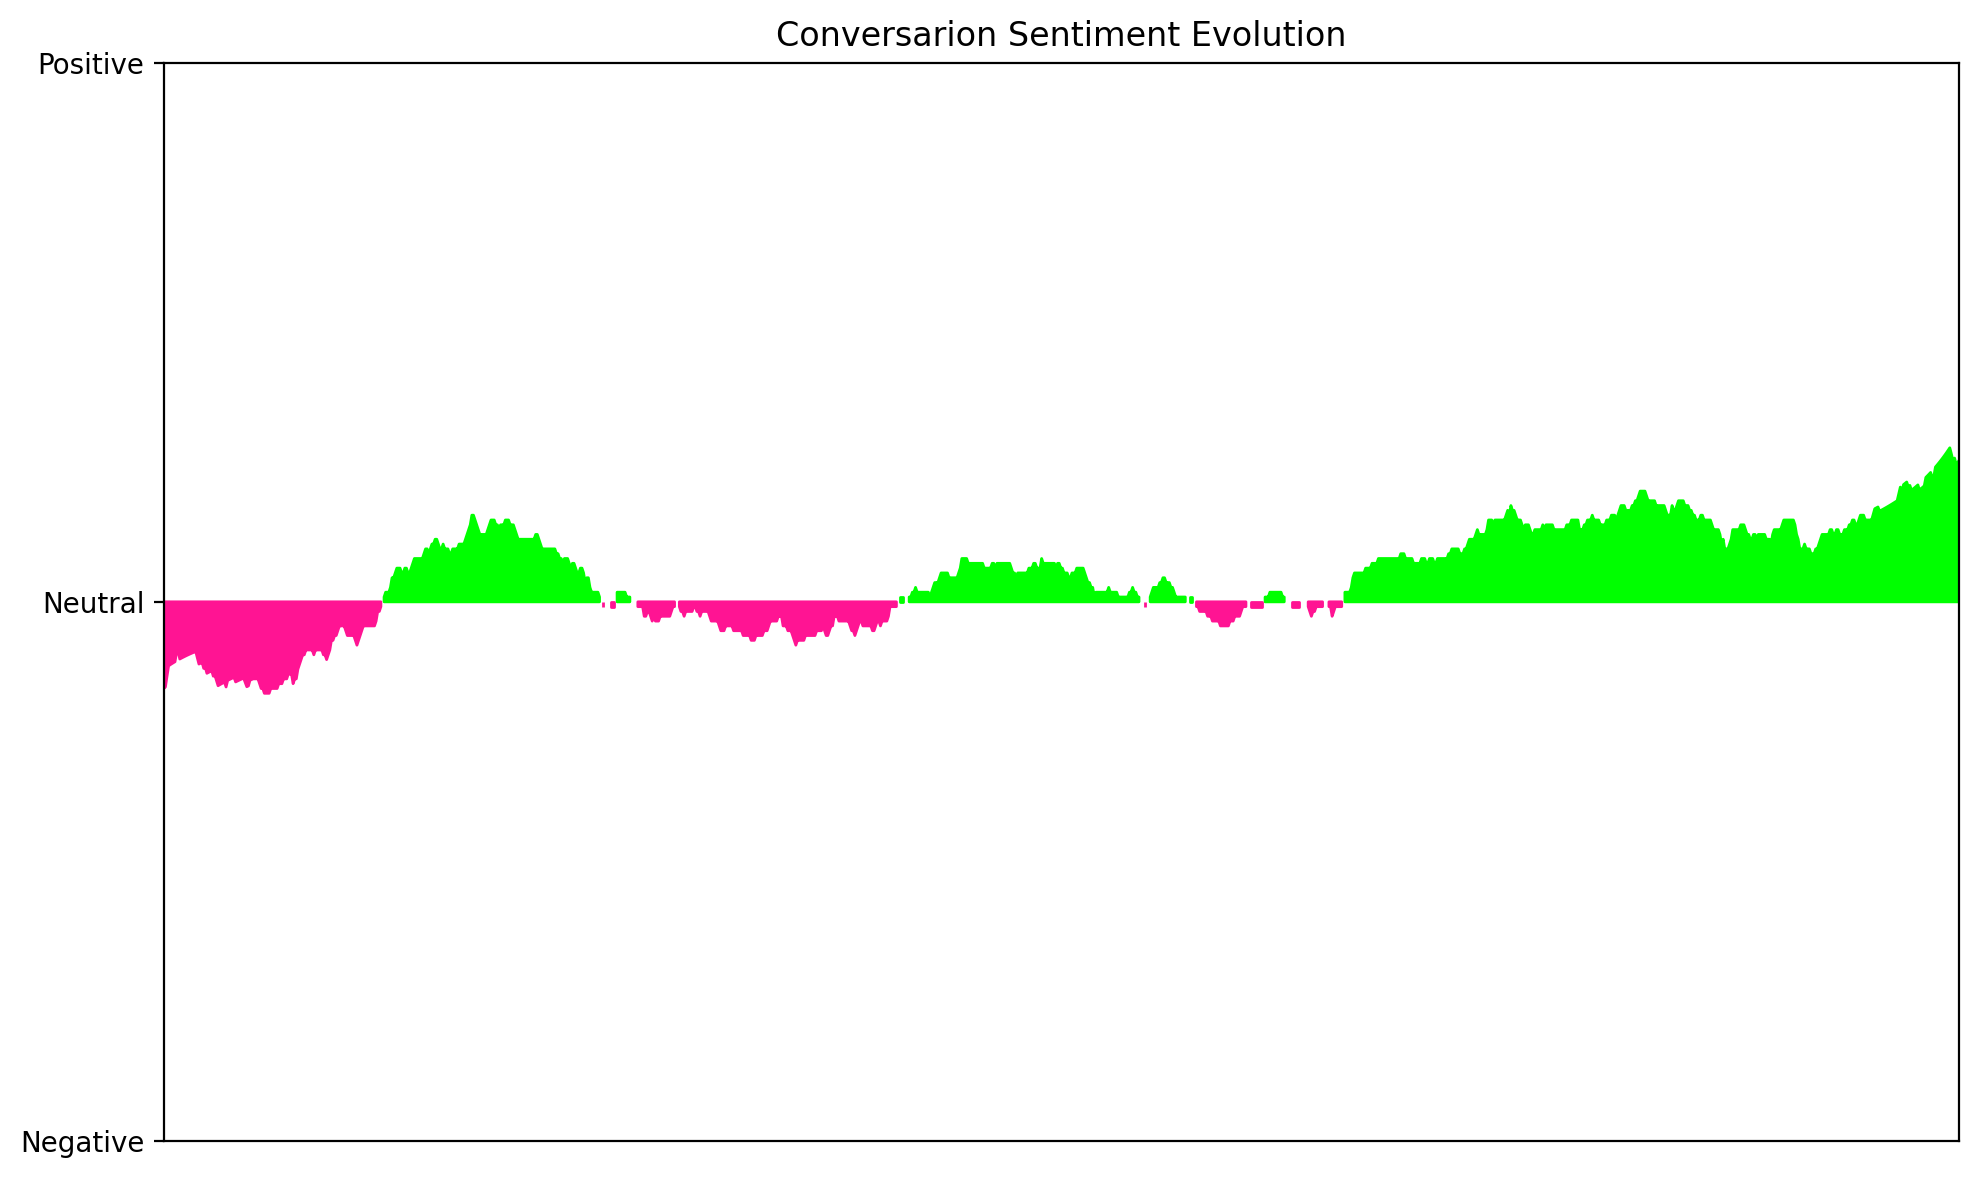

In [42]:
# df_sentiment['sentiment_value'].plot(alpha=0.2)

_window_size_pct = 0.1
_window_size = int(
    df_sentiment['sentiment_value'].shape[0] * _window_size_pct
)  # Window size as percentage
df_sentiment_mean = df_sentiment['sentiment_value'].rolling(window=_window_size, center=True, min_periods=1).mean()
# ax = df_sentiment['sentiment_value'].plot()
ax = df_sentiment_mean.plot(figsize=(10, 6), alpha=0)
ax.set_ylim(-1, 1)
# ax.axhline(y=0, color='lightgray', linestyle='--', linewidth=1)
ax.fill_between(
    df_sentiment_mean.index,
    df_sentiment_mean,
    0,
    where=(df_sentiment_mean > 0),
    color='lime',
    alpha=1,
)
ax.fill_between(
    df_sentiment_mean.index,
    df_sentiment_mean,
    0,
    where=(df_sentiment_mean < 0),
    color='deeppink',
    alpha=1,
)
ax.set_yticks([-1, 0, 1])
ax.set_yticklabels(['Negative', 'Neutral', 'Positive'])
ax.set_xticks([])
ax.set_title('Conversarion Sentiment Evolution')
plt.tight_layout()
plt.autoscale(tight=True, axis='x')
# df_sentiment['sentiment_value'].plot()

## Sentiment evolution per person

In [43]:
df_sentiment[['name','sentiment_value']].describe()#.groupby('name').std()

,name,sentiment_value
count,1126,1126
unique,6,3
top,Mel,0
freq,508,831


In [44]:
df_sentiment.groupby('name')['sentiment_value'].apply(
    lambda x: pd.DataFrame((x.sum(),x.std(),x.mean()), index=('sum','std','mean'))
).unstack().droplevel(0, axis=1).sort_values('mean').style.background_gradient(cmap='RdPu', axis=1)

,sum,std,mean
name,,,
Brandy,-5.000000,0.599709,-0.054348
Daion,-2.000000,0.484192,-0.028986
Jason,8.000000,0.533255,0.036697
Mel,26.000000,0.495879,0.051181
Felipe,9.000000,0.444131,0.078947
Rodrigo,17.000000,0.513432,0.136000


Felipe (114,)


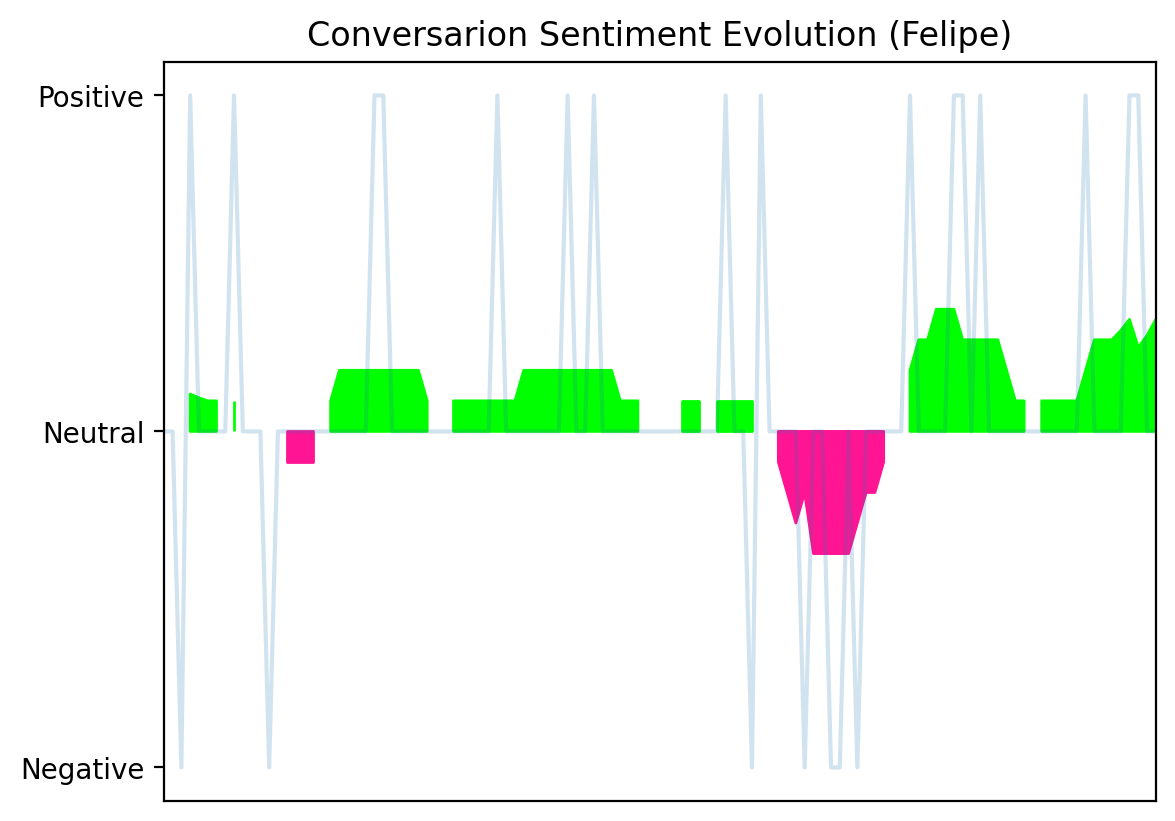

Jason (218,)


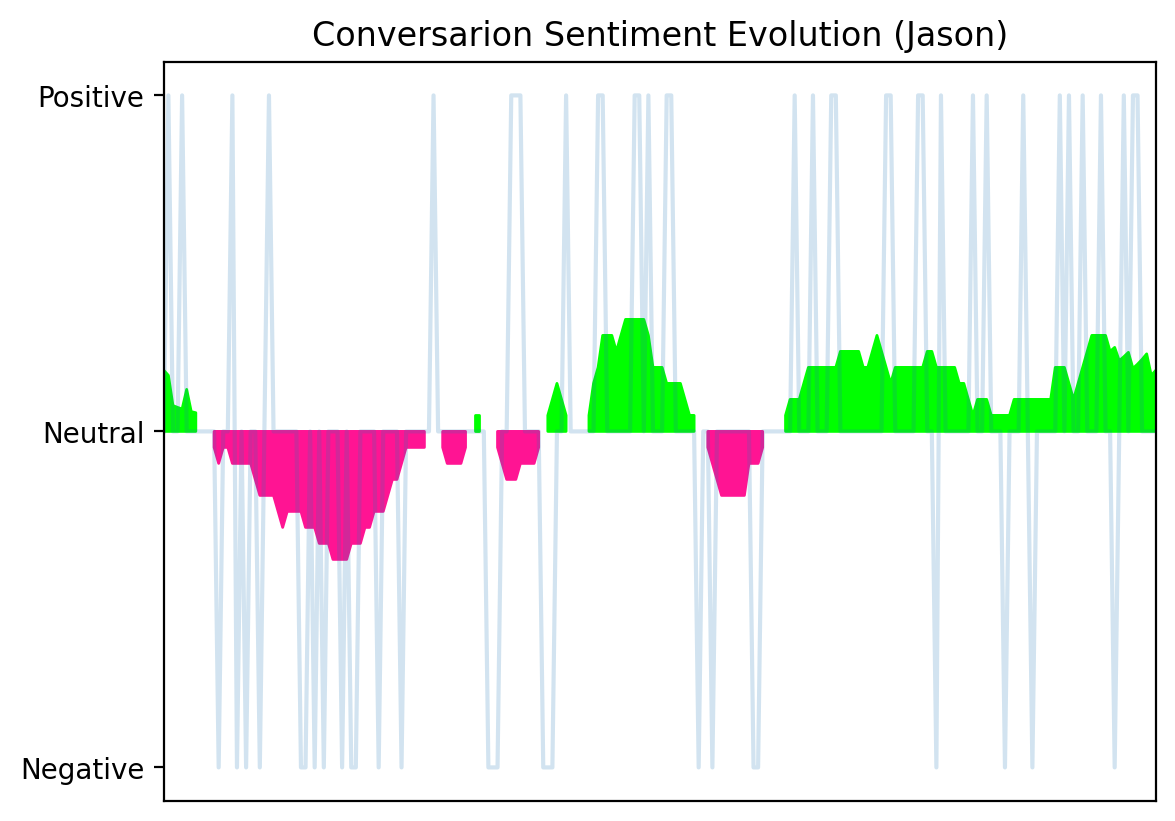

Rodrigo (125,)


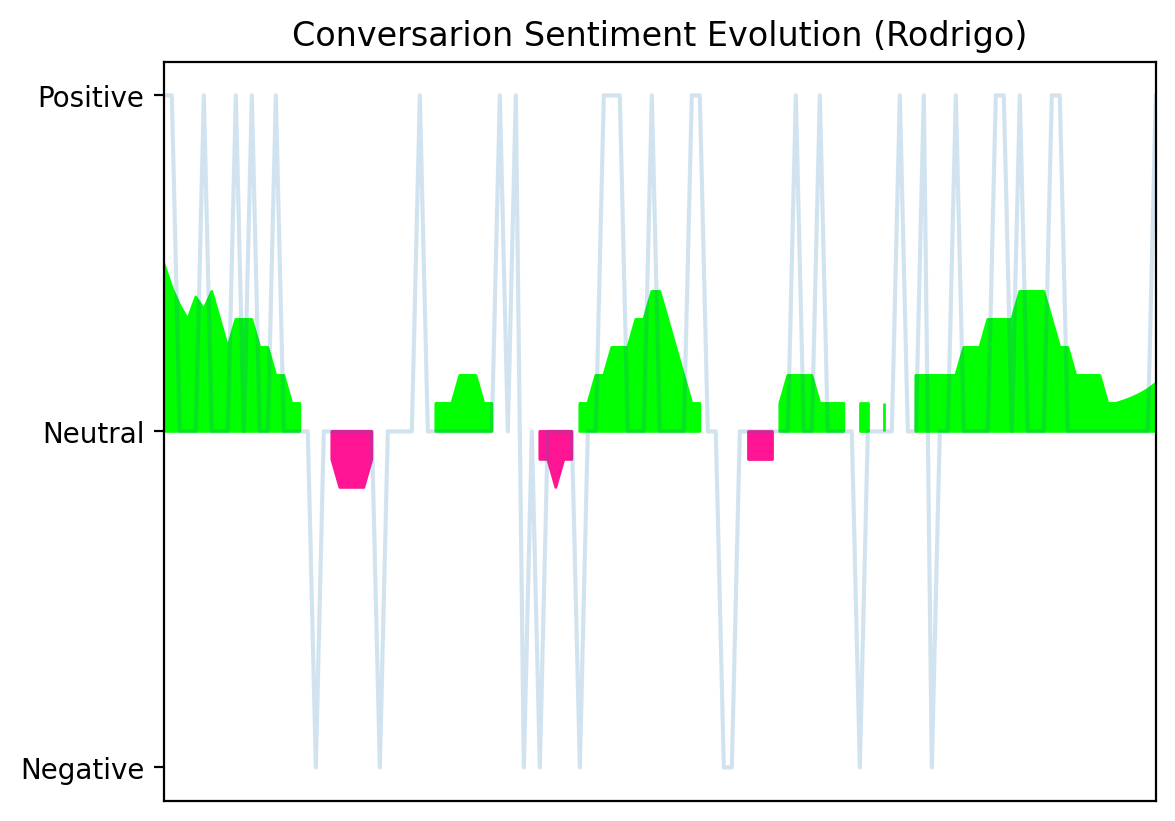

Brandy (92,)


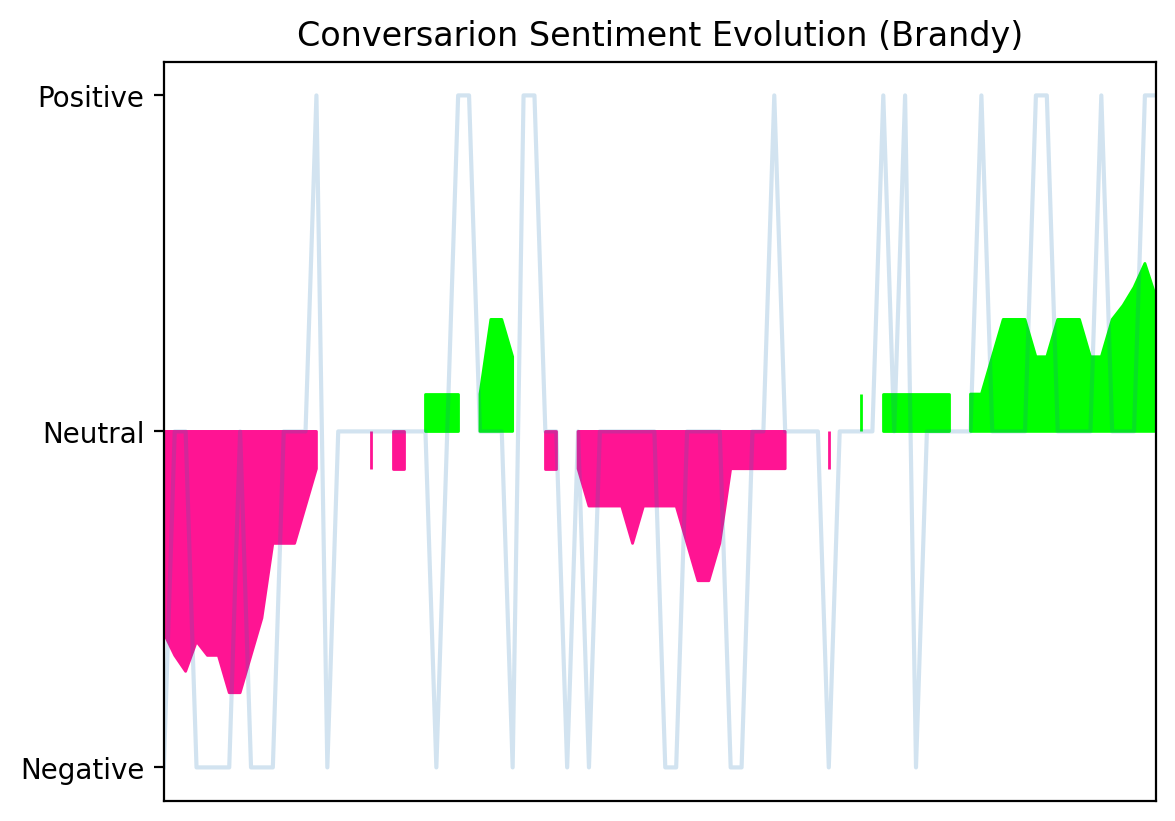

Mel (508,)


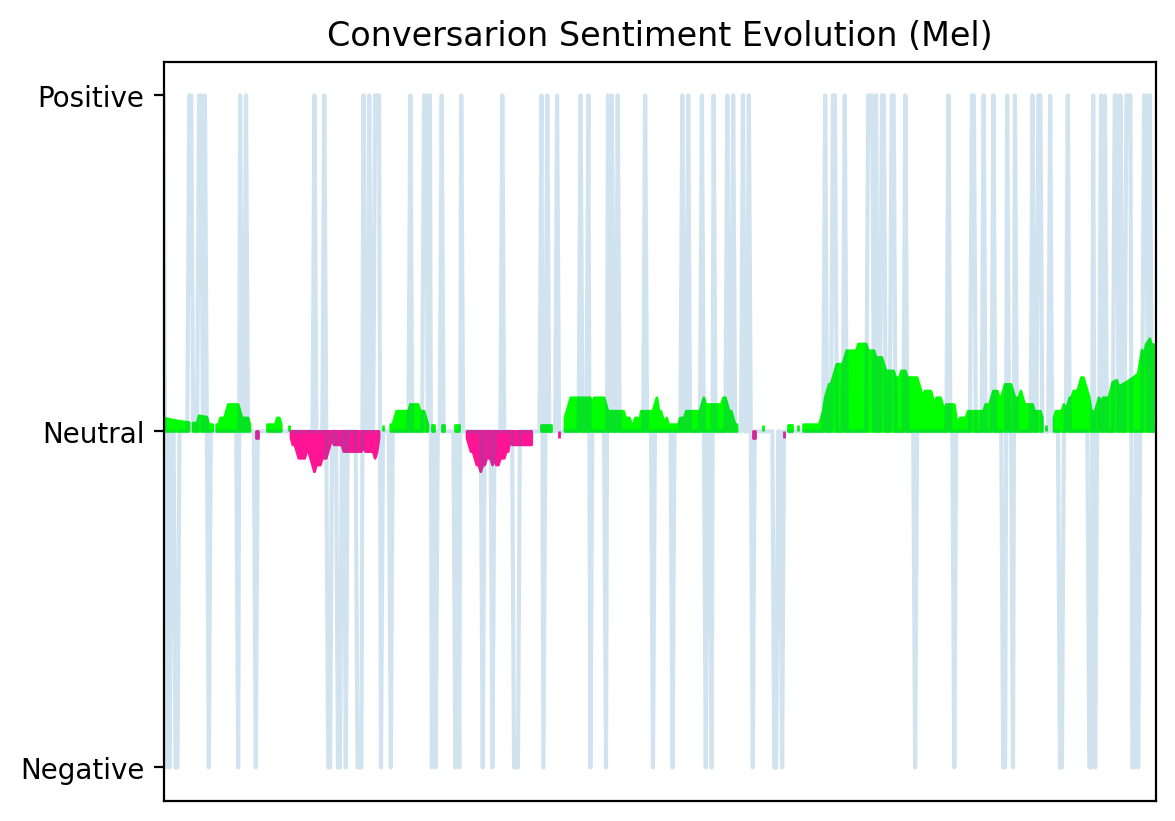

Daion (69,)


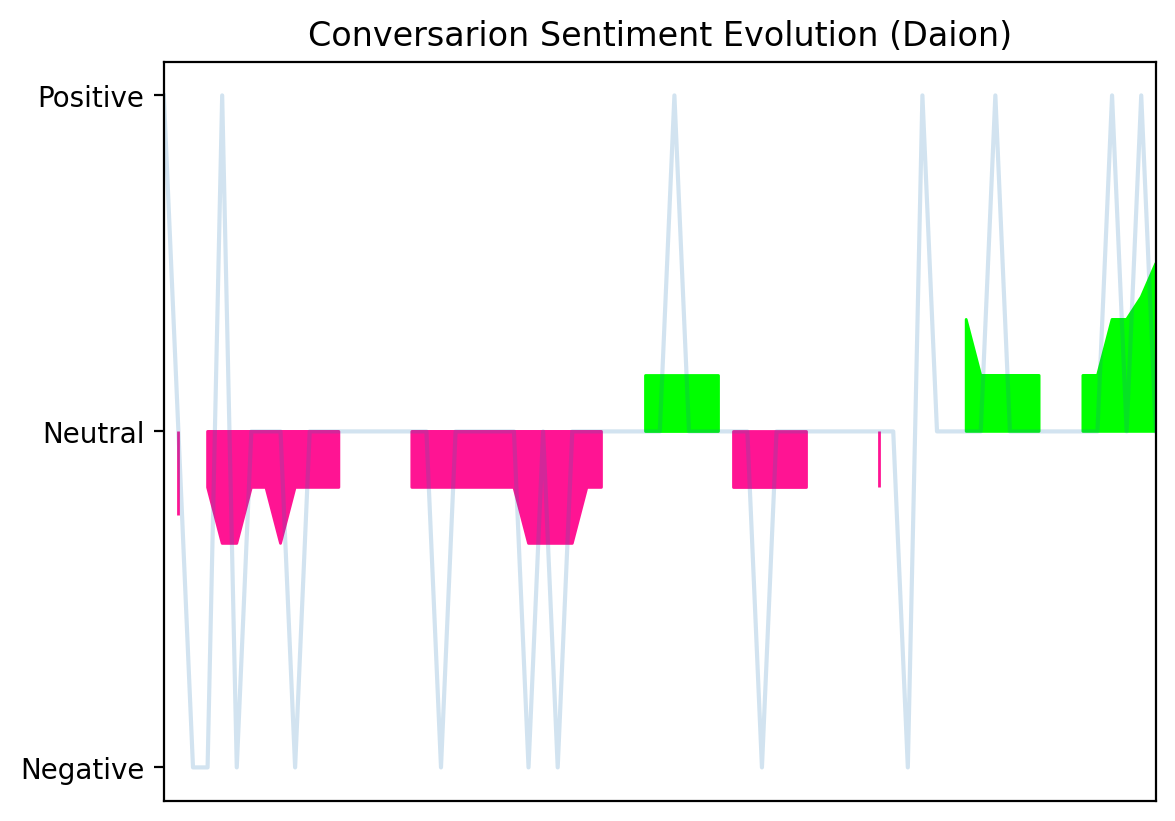

In [45]:
import matplotlib.pyplot as plt

pltlogger = logging.getLogger('matplotlib')
pltlogger.setLevel(logging.WARNING)

for name in df_sentiment['name'].unique():
    _df_sentiment_by_person = df_sentiment.query(f'name == "{name}"')['sentiment_value']

    _df_sentiment_by_person.reset_index(drop=True).plot(
        alpha=0.2,
        )

    # Window size as percentage
    _window_size_pct = 0.10
    _window_size_computed = int(
        _df_sentiment_by_person.shape[0] * _window_size_pct
    )
    _window_size = max(1, _window_size_computed)
    
    # _window_size = 5

    # print(name)
    # print(len(_df_sentiment_by_person), min_periods)
    df_sentiment_mean = (_df_sentiment_by_person
        .reset_index(drop=True)
        .rolling(window=_window_size, center=True, min_periods=1)
        .mean()
        )
    print(name, df_sentiment_mean.shape)
    ax = (
        df_sentiment_mean
        .plot(
            # legend=True,
            alpha=0
        )
    )
    ax.fill_between(df_sentiment_mean.index, df_sentiment_mean, 0, where=(df_sentiment_mean > 0), color='lime', alpha=1)
    ax.fill_between(df_sentiment_mean.index, df_sentiment_mean, 0, where=(df_sentiment_mean < 0), color='deeppink', alpha=1)
    ax.set_yticks([-1, 0, 1])
    ax.set_yticklabels(['Negative', 'Neutral', 'Positive'])
    ax.set_xticks([])
    ax.set_title(f'Conversarion Sentiment Evolution ({name})')
    # plt.tight_layout()
    plt.autoscale(tight=True, axis='x')
    # break
    plt.show()
    
# ax.legend([name for name in df_sentiment['name'].unique()])